<img src="https://raw.githubusercontent.com/drdave-teaching/OPIM5509-notebooks/main/_banners/opim5509_banner.svg" width="100%" alt="OPIM 5509 banner"/>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/drdave-teaching/OPIM5509-notebooks/blob/main/FinalProject/FP2_Probabilistic_LSTM.ipynb)

# Final Project, Part 2: An LSTM That Gives a Range
--------------------------------------------------
**Dr. Dave Wanik - University of Connecticut**

In Part 1 your LSTM made one number per hour. A grid operator needs more than that: "we expect 3,100 MW, and we are
80% sure it will land between 2,950 and 3,300". This notebook teaches the LSTM to give a **low, expected and high**
forecast, scores it the way the class leaderboard does (**CRPS**), and then compares three plug-and-play ways to build
the range with real weather forecasts:

| Option | What makes the range | Card setting |
| :-- | :-- | :-- |
| A | **one LSTM, several weather forecasts**: run it on the 3 newest HRRR weather runs and use how much they disagree | `lstm_hrrr_runs` |
| B | **one probabilistic LSTM, one weather forecast**: the model's own 10th and 90th percentiles | `lstm_quantiles` |
| C | **both**: the model's percentiles on each of the 3 weather runs, pooled | `lstm_quantiles_pooled` |

You pick one for your final project (or invent a better one).

## Part 0 · Before you start
**Runtime > Change runtime type > T4 GPU.** Run Part 1 of the project (`FP1_Basic_LSTM_Forecast`) first; this notebook
uses the same data, the same inputs and the same model, with a new last layer and a new loss.

In [1]:
import json
import time

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
from pandas.tseries.holiday import USFederalHolidayCalendar

SETTINGS = {
    "seed": 5509,
    "lookback_hours": 168,
    "horizon_hours": 24,
    "train_end_utc": "2026-01-01",
    "units": 64,
    "epochs": 30,
    "batch_size": 128,
    "patience": 3,
    "hrrr_runs": 3,                  # how many recent weather runs to use (the newest 3 that reach a full day ahead)
    "hrrr_ready_after_hours": 2,     # a run can be used about 2 hours after it starts
    "backtest_every_hours": 3,       # score every 3rd hour of 2026 in Part 6 (faster; same answer)
}
# 20 percentiles per hour: the middle of each 5% slice of the chances (2.5%, 7.5%, ..., 97.5%)
QUANTILES = []
for k in range(20):
    QUANTILES.append(round(0.025 + 0.05 * k, 3))
keras.utils.set_random_seed(SETTINGS["seed"])
tf.config.experimental.enable_op_determinism()
print("Keras", keras.__version__, "| GPU:", len(tf.config.list_physical_devices("GPU")) > 0)
print("percentiles:", QUANTILES)

Keras 3.15.1 | GPU: False
percentiles: [0.025, 0.075, 0.125, 0.175, 0.225, 0.275, 0.325, 0.375, 0.425, 0.475, 0.525, 0.575, 0.625, 0.675, 0.725, 0.775, 0.825, 0.875, 0.925, 0.975]


## Part 1 · Load the data (same file as Part 1) and the weather forecasts
The second file is every HRRR weather forecast for Bradley airport **as it was issued**: the National Weather
Service's high-resolution model runs at 00, 06, 12 and 18 UTC and forecasts 48 hours ahead. For each run
(`init_utc`) and each hour it forecast (`hour_utc`) we have the five weather variables. That is what lets us test the
model on the forecasts it would really have had, not on weather that already happened.

In [2]:
DATA = "https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/Module4/data/"
df = pd.read_csv(DATA + "bdl_ct_load_hourly_2023_2026.csv", parse_dates=["hour_utc"])
df = df.set_index("hour_utc").sort_index()
all_hours = pd.date_range(df.index.min(), df.index.max(), freq="h")
df = df.reindex(all_hours)
hrrr = pd.read_csv(DATA + "bdl_hrrr_asissued_2023_2026.csv.gz", parse_dates=["init_utc", "hour_utc"])
print(df.shape, "| load and weather from", df.index.min(), "to", df.index.max())
print(hrrr["init_utc"].nunique(), "HRRR runs, each 0-48 hours ahead")

(33215, 17) | load and weather from 2023-01-01 05:00:00+00:00 to 2026-10-16 03:00:00+00:00
5591 HRRR runs, each 0-48 hours ahead


## Part 2 · How the leaderboard scores a range: CRPS
A range has two jobs that pull in opposite directions: be **narrow** (useful) and **contain the truth** (honest).
The leaderboard's score, the 3-percentile **CRPS**, rewards both. For one hour, with your low (10th percentile),
expected (50th) and high (90th) forecasts and the actual load:

$$\text{CRPS} = \frac{0.5\,|\text{actual} - \text{expected}| \; + \; 0.1\,(\text{high} - \text{low}) \; + \; \text{miss}}{1.5}$$

where **miss** is how far the actual landed outside the range (0 if it is inside). It is in megawatts, lower is
better, and a forecast with no range at all scores exactly its absolute error. **CRPS skill** = 1 - (your CRPS / the
error of "same hour yesterday"), in each lead block, averaged.

A well-calibrated 80% range has about **80% of the actual hours inside it**. Below 80% = overconfident.

In [3]:
def crps3(actual, low, expected, high):
    """The leaderboard's 3-percentile CRPS (weighted interval score), in MW, element by element."""
    miss = np.maximum(low - actual, 0) + np.maximum(actual - high, 0)
    return (0.5 * np.abs(actual - expected) + 0.1 * (high - low) + miss) / 1.5


BLOCKS = {"1-6 h": slice(0, 6), "7-12 h": slice(6, 12), "13-18 h": slice(12, 18), "19-24 h": slice(18, 24)}


def skill_table(scores, baseline_errors):
    """CRPS skill by lead block from arrays shaped (forecasts, 24): your CRPS and the baseline's absolute error."""
    rows = []
    skills = []
    for name in BLOCKS:
        mine = float(scores[:, BLOCKS[name]].mean())
        base = float(baseline_errors[:, BLOCKS[name]].mean())
        skills.append(1 - mine / base)
        rows.append({"lead block": name, "baseline error (MW)": round(base), "CRPS (MW)": round(mine), "skill": round(1 - mine / base, 3)})
    return pd.DataFrame(rows), float(np.mean(skills))


# a toy hour: actual 3,000 MW
print("narrow and right  :", crps3(3000, 2950, 3010, 3070))
print("wide and right    :", crps3(3000, 2600, 3010, 3400))
print("narrow and wrong  :", crps3(3000, 3150, 3200, 3250))
print("no range, 10 off  :", crps3(3000, 3010, 3010, 3010))

narrow and right  : 11.333333333333334
wide and right    : 56.666666666666664
narrow and wrong  : 173.33333333333334
no range, 10 off  : 10.0


## Part 3 · The same inputs as Part 1
This cell is copied word for word from Part 1. It is the contract with the cloud function, so it never changes
between notebooks.

In [4]:
WEATHER = ["temp_f", "dewpoint_f", "rel_humidity_pct", "wind_speed_mph", "cloud_cover_pct"]
HOLIDAYS = USFederalHolidayCalendar().holidays(start="2020-01-01", end="2030-12-31")


def calendar_features(hours_utc):
    """Hour of day, day of week and time of year as sines and cosines, plus weekend and holiday flags, in Connecticut time."""
    local = pd.DatetimeIndex(hours_utc).tz_convert("America/New_York")
    out = pd.DataFrame(index=pd.DatetimeIndex(hours_utc))
    out["hour_sin"] = np.sin(2 * np.pi * local.hour / 24)
    out["hour_cos"] = np.cos(2 * np.pi * local.hour / 24)
    out["dow_sin"] = np.sin(2 * np.pi * local.dayofweek / 7)
    out["dow_cos"] = np.cos(2 * np.pi * local.dayofweek / 7)
    out["doy_sin"] = np.sin(2 * np.pi * local.dayofyear / 365.25)
    out["doy_cos"] = np.cos(2 * np.pi * local.dayofyear / 365.25)
    out["is_weekend"] = (local.dayofweek >= 5).astype(float)
    out["is_holiday"] = local.tz_localize(None).normalize().isin(HOLIDAYS).astype(float)
    return out


def make_inputs(issue_hour_utc, load, weather, card):
    """The model's two inputs for ONE forecast issued at issue_hour_utc.
    load: Connecticut load in MW indexed by UTC hour (only hours that are over).
    weather: the WEATHER columns indexed by UTC hour, covering the next 24 hours.
    card: the model card (look-back, horizon and the scaling numbers).
    Returns past (lookback, 3) and future (horizon, 13), both scaled."""
    issue = pd.Timestamp(issue_hour_utc)
    past_hours = pd.date_range(issue - pd.Timedelta(hours=card["lookback_hours"]), periods=card["lookback_hours"], freq="h")
    future_hours = pd.date_range(issue + pd.Timedelta(hours=1), periods=card["horizon_hours"], freq="h")
    past_load = (load.reindex(past_hours).values - card["load_mean"]) / card["load_std"]
    past_cal = calendar_features(past_hours)[["hour_sin", "hour_cos"]].values
    past = np.column_stack([past_load, past_cal])
    future_weather = weather[WEATHER].reindex(future_hours)
    scaled_weather = []
    for column in WEATHER:
        scaled_weather.append((future_weather[column].values - card["weather_mean"][column]) / card["weather_std"][column])
    future = np.column_stack(scaled_weather + [calendar_features(future_hours).values])
    return past.astype("float32"), future.astype("float32")

In [5]:
train_end = pd.Timestamp(SETTINGS["train_end_utc"], tz="UTC")
is_train_hour = df.index < train_end
card = {
    "model_type": "keras_lstm",
    "lookback_hours": SETTINGS["lookback_hours"],
    "horizon_hours": SETTINGS["horizon_hours"],
    "weather_columns": WEATHER,
    "load_mean": float(df.loc[is_train_hour, "load_mw"].mean()),
    "load_std": float(df.loc[is_train_hour, "load_mw"].std()),
    "weather_mean": {},
    "weather_std": {},
}
for column in WEATHER:
    card["weather_mean"][column] = float(df.loc[is_train_hour, column].mean())
    card["weather_std"][column] = float(df.loc[is_train_hour, column].std())

load = df["load_mw"]
weather = df[WEATHER]
lookback = SETTINGS["lookback_hours"]
horizon = SETTINGS["horizon_hours"]
start = time.time()
# make_inputs builds ONE forecast. For 33,000 training samples it is much faster to build the same numbers for every
# hour at once, slide a window over them, and then check a few samples against make_inputs (the code the cloud runs).
hours = df.index
load_scaled = (load.values - card["load_mean"]) / card["load_std"]
scaled_weather = []
for column in WEATHER:
    scaled_weather.append((weather[column].values - card["weather_mean"][column]) / card["weather_std"][column])
calendar = calendar_features(hours)
every_hour_past = np.column_stack([load_scaled, calendar[["hour_sin", "hour_cos"]].values]).astype("float32")
every_hour_future = np.column_stack(scaled_weather + [calendar.values]).astype("float32")

windows_past = np.lib.stride_tricks.sliding_window_view(every_hour_past, lookback, axis=0)        # window k = hours k ... k+167
windows_future = np.lib.stride_tricks.sliding_window_view(every_hour_future, horizon, axis=0)    # window k = hours k ... k+23
windows_load = np.lib.stride_tricks.sliding_window_view(load_scaled.astype("float32"), horizon)
issue_positions = np.arange(lookback, len(hours) - horizon)
past_all = windows_past[issue_positions - lookback].transpose(0, 2, 1)        # the 168 hours before the issue hour
future_all = windows_future[issue_positions + 1].transpose(0, 2, 1)           # the 24 hours after it
y_all = windows_load[issue_positions + 1]
missing = np.isnan(past_all).any(axis=(1, 2)) | np.isnan(future_all).any(axis=(1, 2)) | np.isnan(y_all).any(axis=1)
X_past = np.ascontiguousarray(past_all[~missing])
X_future = np.ascontiguousarray(future_all[~missing])
y = np.ascontiguousarray(y_all[~missing])
issue_hours = hours[issue_positions[~missing]]
train = issue_hours < train_end

# the check: 5 random samples, built the slow way with make_inputs, must match
rng = np.random.default_rng(SETTINGS["seed"])
for k in rng.choice(len(y), 5, replace=False):
    past, future = make_inputs(issue_hours[k], load, weather, card)
    if not (np.allclose(past, X_past[k], atol=1e-5) and np.allclose(future, X_future[k], atol=1e-5)):
        raise ValueError("The fast sequences do not match make_inputs at " + str(issue_hours[k]))
print("5 random samples match make_inputs exactly")
print("samples:", len(y), "| train", int(train.sum()), "| test (2026)", int((~train).sum()), f"| built in {time.time() - start:.0f} s")

5 random samples match make_inputs exactly
samples: 33023 | train 26131 | test (2026) 6892 | built in 0 s


## Part 4 · Teach the LSTM to give percentiles: the pinball loss
The only changes from Part 1:
* the last layer has **20 outputs per hour**, one for each percentile, instead of 1;
* the loss is the **pinball loss**. For the 90th percentile, forecasting too low costs 9 times as much as
  forecasting too high, so the model learns to put its 90th percentile where the load is below it 90% of the time.
  Every percentile gets its own lopsided penalty, and the 50th is the plain absolute error from Part 1.

In [6]:
Q = np.array(QUANTILES, dtype="float32")


def pinball_loss(y_true, y_pred):
    """Average pinball (quantile) loss over the 24 hours and the 20 percentiles.
    y_true: (batch, 24) actual loads.  y_pred: (batch, 24, 20) the percentiles."""
    error = keras.ops.expand_dims(y_true, -1) - y_pred
    return keras.ops.mean(keras.ops.maximum(Q * error, (Q - 1) * error))


keras.utils.set_random_seed(SETTINGS["seed"])          # re-seed before every build
past_in = keras.Input(shape=(lookback, X_past.shape[2]), name="past")
future_in = keras.Input(shape=(horizon, X_future.shape[2]), name="future")
summary = layers.LSTM(SETTINGS["units"], name="read_the_past_week")(past_in)
repeated = layers.RepeatVector(horizon)(summary)
merged = layers.Concatenate()([repeated, future_in])
sequence = layers.LSTM(SETTINGS["units"], return_sequences=True, name="read_the_next_24_hours")(merged)
percentiles = layers.TimeDistributed(layers.Dense(len(QUANTILES)), name="percentiles_next_24h")(sequence)
model = keras.Model(inputs=[past_in, future_in], outputs=percentiles)
model.compile(optimizer="adam", loss=pinball_loss)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ past (InputLayer)   │ (None, 168, 3)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ read_the_past_week  │ (None, 64)        │     17,408 │ past[0][0]        │
│ (LSTM)              │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector       │ (None, 24, 64)    │          0 │ read_the_past_we… │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ future (InputLayer) │ (None, 24, 13)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 24, 77)    │          0 │ repeat_vector[0]… │
│ (Concatenate)       │                   │            │ future[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ read_the_next_24_h… │ (None, 24, 64)    │     36,352 │ concatenate[0][0] │
│ (LSTM)              │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ percentiles_next_2… │ (None, 24, 20)    │      1,300 │ read_the_next_24… │
│ (TimeDistributed)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 55,060 (215.08 KB)

 Trainable params: 55,060 (215.08 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30


174/174 - 26s - 148ms/step - loss: 0.1539 - val_loss: 0.0777


Epoch 2/30


174/174 - 22s - 125ms/step - loss: 0.0637 - val_loss: 0.0575


Epoch 3/30


174/174 - 22s - 126ms/step - loss: 0.0516 - val_loss: 0.0526


... (31 outputs left out)

174/174 - 21s - 121ms/step - loss: 0.0319 - val_loss: 0.0435


Epoch 20/30


174/174 - 22s - 126ms/step - loss: 0.0314 - val_loss: 0.0435


fit in 437 s


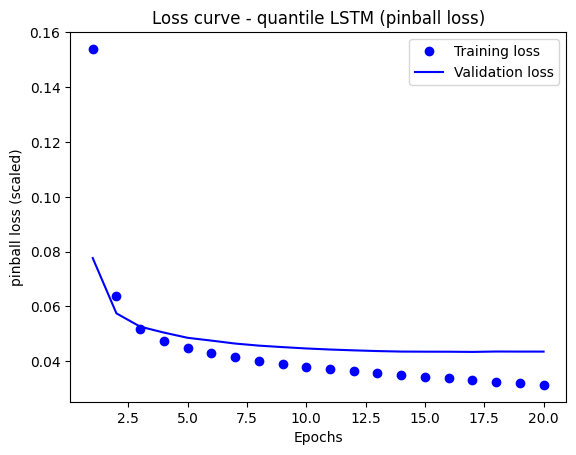

epochs run: 20 | best validation loss: 0.0434 at epoch 17


In [7]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=SETTINGS["patience"], restore_best_weights=True)
start = time.time()
history = model.fit([X_past[train], X_future[train]], y[train],
                    validation_split=0.15,
                    epochs=SETTINGS["epochs"],
                    batch_size=SETTINGS["batch_size"],
                    callbacks=[early_stop],
                    verbose=2)
print(f"fit in {time.time() - start:.0f} s")

# loss curve - always look at this after a fit!
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(loss) + 1)
plt.plot(epochs, loss, "bo", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Loss curve - quantile LSTM (pinball loss)")
plt.xlabel("Epochs")
plt.ylabel("pinball loss (scaled)")
plt.legend()
plt.show()
print("epochs run:", len(loss), "| best validation loss:", round(min(val_loss), 4), "at epoch", val_loss.index(min(val_loss)) + 1)

## Part 5 · Score it on 2026, with the weather that actually happened
Twenty percentiles come out per hour. Percentiles can cross (the 60th a hair below the 55th), so we sort them, then
read the low, expected and high exactly the way the cloud function does: `np.quantile(..., [0.1, 0.5, 0.9],
method="hazen")`. This first score is **optimistic**: the model was handed the real weather.

In [8]:
def low_expected_high(piles):
    """10th, 50th and 90th percentile of each pile. piles: (forecasts, 24, values) -> three arrays (forecasts, 24)."""
    out = np.quantile(np.sort(piles, axis=-1), [0.1, 0.5, 0.9], axis=-1, method="hazen")
    return out[0], out[1], out[2]


def to_mw(scaled):
    return scaled * card["load_std"] + card["load_mean"]


actual_test = to_mw(y[~train])
baseline_test = []
for issue in issue_hours[~train]:
    target_hours = pd.date_range(issue + pd.Timedelta(hours=1), periods=horizon, freq="h")
    baseline_test.append(load.reindex(target_hours - pd.Timedelta(hours=24)).values)
baseline_test = np.array(baseline_test)
baseline_error = np.abs(baseline_test - actual_test)

pred = to_mw(model.predict([X_past[~train], X_future[~train]], verbose=0))
low, expected, high = low_expected_high(pred)
table, skill = skill_table(crps3(actual_test, low, expected, high), baseline_error)
inside = float(((actual_test >= low) & (actual_test <= high)).mean())
print(f"CRPS skill {skill:.3f} | {inside:.0%} of hours inside the 80% range | average width {float((high - low).mean()):.0f} MW")
table

CRPS skill 0.742 | 59% of hours inside the 80% range | average width 210 MW


,lead block,baseline error (MW),CRPS (MW),skill
0,1-6 h,266,66,0.752
1,7-12 h,266,70,0.736
2,13-18 h,266,70,0.738
3,19-24 h,266,69,0.743


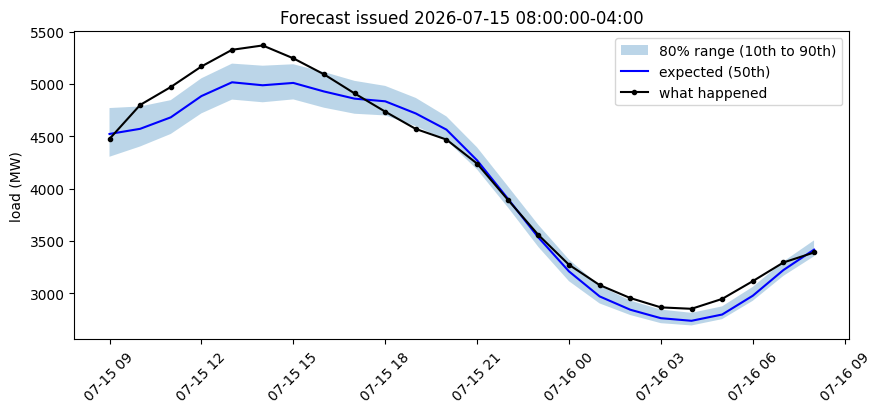

In [9]:
# one day up close: the range as a ribbon
issue_local = pd.Timestamp("2026-07-15 08:00", tz="America/New_York")
k = int(np.argmin(np.abs((issue_hours[~train] - issue_local.tz_convert("UTC")).total_seconds())))
target_hours = pd.date_range(issue_hours[~train][k] + pd.Timedelta(hours=1), periods=horizon, freq="h").tz_convert("America/New_York")
plt.figure(figsize=(10, 4))
plt.fill_between(target_hours, low[k], high[k], alpha=0.3, label="80% range (10th to 90th)")
plt.plot(target_hours, expected[k], "b-", label="expected (50th)")
plt.plot(target_hours, actual_test[k], "k.-", label="what happened")
plt.title("Forecast issued " + str(issue_hours[~train][k].tz_convert("America/New_York")))
plt.ylabel("load (MW)")
plt.legend()
plt.xticks(rotation=45)
plt.show()

## Part 6 · The real test: 2026 with the weather forecasts it would have had
In the cloud the model never sees tomorrow's real weather, only forecasts. Here every 2026 forecast (every 3rd hour,
to keep it quick) uses the HRRR runs that existed at that moment. A run is ready about 2 hours after it starts, and
each run forecasts 48 hours ahead, so at any moment the **3 newest ready runs** all reach a full day ahead (the
LSTM needs all 24 hours of weather). Then the three plug-and-play options from the top of the notebook.

In [10]:
runs = {}
for init, table_run in hrrr.groupby("init_utc"):
    runs[init] = table_run.set_index("hour_utc")[WEATHER]
inits = pd.DatetimeIndex(sorted(runs.keys()))

test_positions = np.where(~train)[0][::SETTINGS["backtest_every_hours"]]
n_runs = SETTINGS["hrrr_runs"]
ready = pd.Timedelta(hours=SETTINGS["hrrr_ready_after_hours"])
start = time.time()
past_bt = []
future_bt = []
keep = []
for position in test_positions:
    issue = issue_hours[position]
    usable = inits[(inits <= issue - ready) & (inits + pd.Timedelta(hours=48) >= issue + pd.Timedelta(hours=horizon))]
    if len(usable) < n_runs:
        continue
    futures = []
    for init in usable[-n_runs:]:
        past, future = make_inputs(issue, load, runs[init], card)
        futures.append(future)
    stacked = np.stack(futures)
    if np.isnan(stacked).any():
        continue
    past_bt.append(past)
    future_bt.append(stacked)
    keep.append(position)
past_bt = np.stack(past_bt)                  # (forecasts, 168, 3)
future_bt = np.stack(future_bt)              # (forecasts, runs, 24, 13), newest run LAST
keep = np.array(keep)
print(len(keep), "forecasts in 2026 with", n_runs, f"HRRR runs each | built in {time.time() - start:.0f} s")

# predict every forecast with every run: (forecasts, runs, 24, 20)
per_run = []
for r in range(n_runs):
    per_run.append(to_mw(model.predict([past_bt, future_bt[:, r]], verbose=0)))
per_run = np.stack(per_run, axis=1)
actual_bt = to_mw(y[keep])
baseline_bt = baseline_error[np.searchsorted(np.where(~train)[0], keep)]

2298 forecasts in 2026 with 3 HRRR runs each | built in 57 s


In [11]:
options = {}

# point forecast only: the newest run's 50th percentile, no range
newest = per_run[:, -1]
point = np.quantile(np.sort(newest, axis=-1), 0.5, axis=-1, method="hazen")
options["no range (newest run)"] = (point, point, point)

# A: one LSTM, several weather forecasts - the runs' expected values, and how much they disagree
medians = np.quantile(np.sort(per_run, axis=-1), 0.5, axis=-1, method="hazen")        # (forecasts, runs, 24)
options["A: 3 weather runs"] = low_expected_high(np.moveaxis(medians, 1, -1))

# B: one probabilistic LSTM, one weather forecast - the newest run's own percentiles
options["B: model percentiles, newest run"] = low_expected_high(newest)

# C: both - every run's 20 percentiles in one pile (3 runs x 20 = 60 values per hour)
pooled = np.moveaxis(per_run, 1, 2).reshape(per_run.shape[0], horizon, -1)
options["C: both, pooled"] = low_expected_high(pooled)

rows = []
for name in options:
    lo, mid, hi = options[name]
    table_opt, skill_opt = skill_table(crps3(actual_bt, lo, mid, hi), baseline_bt)
    rows.append({"option": name, "CRPS skill": round(skill_opt, 3),
                 "hours inside the range": f"{float(((actual_bt >= lo) & (actual_bt <= hi)).mean()):.0%}",
                 "average width (MW)": round(float((hi - lo).mean())),
                 "expected-value error (MW)": round(float(np.abs(actual_bt - mid).mean()))})
bakeoff = pd.DataFrame(rows)
bakeoff

,option,CRPS skill,hours inside the range,average width (MW),expected-value error (MW)
0,no range (newest run),0.515,0%,0,129
1,A: 3 weather runs,0.575,15%,75,130
2,"B: model percentiles, newest run",0.658,48%,206,129
3,"C: both, pooled",0.669,52%,230,129


**How to read it.** Real forecasts cost accuracy compared with Part 5 - that is the price of not knowing tomorrow's
weather. Option A's range usually comes out far too narrow: weather runs mostly agree with each other, and the model's
own uncertainty is missing. Option B knows about the model's mistakes but not about weather mistakes (it was trained
on weather that actually happened). Option C has both kinds of uncertainty in its pile, which is why it usually does
best. If your best option still has fewer than 80% of hours inside, the range is too narrow: widen it, or train on
as-issued forecasts instead of observed weather (see Your turn).

## Part 7 · Save it for the cloud
Pick one option with `range_method` below. The cloud function (`forecast-24h-dl`) reads the card and builds the range
the same way as Part 6: every hour it reads the class file of recent HRRR runs, keeps the newest runs that reach a full
day ahead, and falls back to the National Weather Service forecast if that file is ever missing.

In [12]:
card["range_method"] = "lstm_quantiles_pooled"      # or "lstm_quantiles" (B) or "lstm_hrrr_runs" (A)
card["quantiles"] = QUANTILES
card["hrrr_runs"] = SETTINGS["hrrr_runs"]
card["trained_at"] = pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%dT%H:%M:%SZ")
card["backtest_2026"] = rows
model.save("model.keras")
with open("model_card.json", "w") as f:
    json.dump(card, f, indent=1)

reloaded = keras.models.load_model("model.keras", compile=False)        # the cloud never trains, so no loss needed
check = to_mw(reloaded.predict([X_past[~train][:5], X_future[~train][:5]], verbose=0))
print("reloaded model reproduces the predictions:", bool(np.allclose(check, pred[:5], atol=0.5)))
print("saved: model.keras and model_card.json with range_method", card["range_method"])

reloaded model reproduces the predictions: True
saved: model.keras and model_card.json with range_method lstm_quantiles_pooled


## Part 8 · Ship it to your energy project
Your energy project on Google Cloud (built once with the
[Energy Project Setup Guide](https://github.com/drdave-teaching/OPIM5509-notebooks/blob/main/FinalProject/Energy_Project_Setup_5509.ipynb)) runs **`forecast-24h-dl`** every hour at :20. It loads
`energy/models/model.keras` and `model_card.json` from your bucket, builds the two inputs with the same `make_inputs` as
this notebook (the last week of live load from your ISO-NE scraper, and the newest HRRR weather forecasts), and writes the
next 24 hours to `energy/forecasts/latest.csv`.

**Once, before the first deploy:** on your fork, Settings > Secrets and variables > Actions > Variables, add
`COURSE` = `5509`, then Actions > "Deploy forecast-24h-dl" > Run workflow. (Without `COURSE`, that workflow stops
with a message and changes nothing.)

Type your project ID, set `UPLOAD = True`, and run the cells below. When the **"Allow access"** pop-up opens,
pick the **Gmail you used for Google Cloud**.

In [13]:
PROJECT_ID = "YOUR-ENERGY-PROJECT-ID"
BUCKET_NAME = PROJECT_ID              # your bucket has the same name as your project (setup guide)
UPLOAD = False                       # True once your energy project is set up

if UPLOAD and ("YOUR-ENERGY-PROJECT-ID" in PROJECT_ID or "YOUR-ENERGY-PROJECT-ID" in BUCKET_NAME):
    print("Type your PROJECT_ID and BUCKET_NAME above, then re-run this cell.")
    UPLOAD = False

if UPLOAD:
    from google.colab import auth
    from google.cloud import storage
    auth.authenticate_user()

    # CHECK 1: which Google account did you just pick in the pop-up?
    account_lines = !gcloud config get-value account
    signed_in_as = "unknown"
    if len(account_lines) > 0:
        signed_in_as = account_lines[-1].strip()
    print("1. Signed in as:", signed_in_as)

    # CHECK 2: can that account see your bucket?
    client = storage.Client(project=PROJECT_ID)
    bucket = client.bucket(BUCKET_NAME)
    try:
        bucket_ok = bucket.exists()
    except Exception as err:
        bucket_ok = False
        print("   Google says:", str(err)[:200])
    if not bucket_ok:
        raise RuntimeError("The account " + signed_in_as + " cannot see the bucket " + BUCKET_NAME + ". "
                           "Check BUCKET_NAME, or Runtime > Disconnect and delete runtime, then run again "
                           "and pick your Google Cloud Gmail in the pop-up.")
    print("2. Bucket found:", BUCKET_NAME)

    # CHECK 3: is forecast-24h-dl deployed?
    state_lines = !gcloud functions describe forecast-24h-dl --gen2 --region=us-central1 --project={PROJECT_ID} --format="value(state)"
    state = "NOT FOUND"
    if len(state_lines) > 0 and state_lines[-1].strip() in ["ACTIVE", "DEPLOYING", "FAILED"]:
        state = state_lines[-1].strip()
    print("3. forecast-24h-dl:", state)
    if state != "ACTIVE":
        print("   Add the repository variable COURSE = 5509, run 'Deploy forecast-24h-dl' on your fork's Actions tab, wait for green, then re-run this cell.")
else:
    print("UPLOAD is False: nothing is uploaded (the model is saved in this Colab session only).")

UPLOAD is False: nothing is uploaded (the model is saved in this Colab session only).


**Upload.** `energy/models/model.keras` is the **live** model (replaced every time you ship);
`energy/models/history/` keeps a copy of every model you ever shipped, named by time.

In [14]:
if UPLOAD:
    bucket.blob("energy/models/model.keras").upload_from_filename("model.keras")
    bucket.blob("energy/models/model_card.json").upload_from_filename("model_card.json")
    stamp = card["trained_at"].replace(":", "-")
    bucket.blob("energy/models/history/model_" + stamp + ".keras").upload_from_filename("model.keras")
    bucket.blob("energy/models/history/model_card_" + stamp + ".json").upload_from_filename("model_card.json")
    print("Live model:  gs://" + BUCKET_NAME + "/energy/models/model.keras", "| range_method:", card["range_method"])
    print("Kept a copy: gs://" + BUCKET_NAME + "/energy/models/history/model_" + stamp + ".keras")
else:
    print("UPLOAD is False: skipping.")

UPLOAD is False: skipping.


**Run it now.** Normally it runs by itself every hour at :20. This cell starts it right now, then checks your bucket
every 15 seconds and shows the forecast.

In [15]:
if UPLOAD:
    from datetime import datetime, timezone
    started = datetime.now(timezone.utc)
    !gcloud scheduler jobs run forecast-24h-dl-hourly --location=us-central1 --project={PROJECT_ID}
    print("Started forecast-24h-dl. Waiting for your forecast", end="")
    latest_blob = bucket.blob("energy/forecasts/latest.csv")
    ready = False
    for attempt in range(20):                 # every 15 seconds, for up to 5 minutes
        time.sleep(15)
        print(".", end="")
        if latest_blob.exists():
            latest_blob.reload()
            if latest_blob.updated > started:
                ready = True
                break
    print()
    if ready:
        import io
        latest = pd.read_csv(io.BytesIO(latest_blob.download_as_bytes()))
        print(latest[["target_hour_utc", "predicted_low_mw", "predicted_load_mw", "predicted_high_mw", "range_method"]].head(6))
    else:
        print("No new forecast after 5 minutes. Run the log cell below and paste the log into Claude.")
else:
    print("UPLOAD is False: skipping.")

UPLOAD is False: skipping.


**Optional, only for troubleshooting.** `"no_load_data"` means your ISO-NE secrets are missing or the scraper has not
collected a full week yet; `"no_model"` means the upload didn't run; `"bad_card"` explains what the card is missing;
anything with `Error` is worth pasting into Claude. A `range_method` ending in `_nws` means the class HRRR file was
missing, so the National Weather Service forecast was used instead (that's fine).

In [16]:
if UPLOAD:
    !gcloud functions logs read forecast-24h-dl --region=us-central1 --gen2 --limit=20 --project={PROJECT_ID}
else:
    print("UPLOAD is False: no log to read.")

UPLOAD is False: no log to read.


## Your turn (pick at least one for the final project)
* **Train on forecasts, not on the weather that happened.** Build the training inputs from the HRRR archive (the run
  that existed at each issue hour) so the model learns how wrong forecasts are. Does Option B catch up with C?
* **Widen honestly.** Find the factor that puts 80% of 2025's hours inside the range, then check 2026.
* **A deep ensemble.** Train 5 copies of the Part 1 LSTM with different seeds and use their spread as the range.
  Is it overconfident, like Option A?
* **More weather and features.** More airports, other forecast models (GFS, ECMWF) through the `hefty` package,
  degree hours, holidays that move. New inputs need forecasts every hour in production too: your own pipeline.
* **A different network.** GRU, a Conv1D in front, or a longer look-back - keep `make_inputs` in sync with the cloud.